# Ejercicio 5: fine-tuning de YOLOv8-seg para mejorar la segmentación

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

En la práctica anterior (Ejercicio 4, segmentación con YOLOv8) incluir un esquema de **fine-tuning** para mejorar la segmentación.

## Qué se hace aquí

El modelo del Ejercicio 4, `yolov8n-seg.pt`, viene entrenado con COCO (80 clases). Para "perro" tiene una sola clase: no sabe distinguir una raza de otra. Aquí se le enseña una tarea nueva y concreta:

- **clase 0, `labrador`**: un Labrador Retriever;
- **clase 1, `gato`**: cualquier otro perro, de cualquier otra raza.

**Aviso sobre el nombre de la clase 1.** Llamar "gato" a los perros que no son labradores es una **convención de esta práctica**, pedida así para tener dos clases con muchas razas en una de ellas. No hay gatos reales en el conjunto de datos. Lo que el modelo aprende es "¿este perro es labrador o no?", y eso es más difícil de lo que parece, porque hay razas muy parecidas a un labrador (Chesapeake Bay Retriever, Flat Coated Retriever).

## El esquema de fine-tuning

Fine-tuning es partir de los pesos ya entrenados en vez de empezar de cero, y seguir entrenando con datos propios y una tasa de aprendizaje pequeña. Se comparan tres modelos, todos sobre el **mismo conjunto de prueba**:

| Modelo | Qué es |
|---|---|
| **Baseline** | `yolov8n-seg.pt` tal cual, sin entrenar nada |
| **Completo** | fine-tuning de **toda** la red (`freeze=None`) |
| **Congelado** | fine-tuning con el **backbone congelado** (`freeze=10`: las 10 primeras capas no se actualizan, solo se entrena el cuello y la cabeza) |

Congelar el backbone es la variante clásica cuando hay pocos datos: entrena menos parámetros, es más rápido y conserva mejor lo que el modelo ya sabía. El costo es que las características de bajo nivel no se pueden adaptar a la tarea nueva.

---

## 1. Entorno

In [1]:
# En local ya viene instalado. En Google Colab: %pip install -q -U ultralytics pyarrow
import json, io, shutil, subprocess, sys, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

plt.rcParams["figure.dpi"] = 70
CARP = Path("ejercicio5_finetune")          # scripts, resultados y pesos de esta practica
DATOS = CARP / "_datos"                      # dataset y fotos descargadas (no se sube al repositorio)
DATASET = DATOS / "dataset"
NOMBRES = {0: "labrador", 1: "gato"}
COLORES = {0: (230, 90, 40), 1: (40, 120, 220)}   # RGB: labrador naranja, "gato" azul

---

## 2. El dataset

### De dónde sale

**Stanford Dogs** (120 razas de perro, unas 150 imágenes por raza), en el espejo de Hugging Face `amaye15/stanford-dogs`. Se usan **todos los labradores** y **8 imágenes candidatas de cada una de 30 razas** distintas, que pasan a ser la clase "gato".

### El problema: Stanford Dogs no trae máscaras

Trae etiqueta de raza y caja, pero no el contorno del animal, y segmentar necesita ese contorno. Anotar a mano 400 imágenes no era viable, así que las máscaras se **generaron automáticamente**:

1. `yolov8m-seg.pt` (el modelo mediano de COCO, mucho más preciso que el nano) segmenta el "perro" de cada foto.
2. La raza decide la clase: labrador es 0, todo lo demás es 1.
3. Se descartan las pseudo-etiquetas dudosas: confianza menor a 0.5, perro que ocupa menos del 6% de la imagen, o más de un perro apreciable en la foto.

> **Advertencia importante.** Estas máscaras son **pseudo-etiquetas de otro modelo YOLO, no anotación humana**. Tienen los errores de ese modelo (bordes imprecisos en el pelaje, una pata de menos), y el modelo que se entrena aquí no puede ser mejor que ellas en el contorno: en el mejor de los casos las reproduce. Lo que sí aprende de verdad es la **distinción de clase**, porque esa etiqueta (raza) sí es real, humana y viene del dataset.

### Imágenes sueltas y collages

Cada imagen se reescala a 640x640 con bordes grises. Además se arman **collages 2x2** con cuatro perros de razas distintas (en la mitad hay al menos un labrador), para que haya varias instancias por imagen. El reparto 70/15/15 se hace **por foto de origen y antes de armar los collages**, así que una misma foto nunca está en entrenamiento y en prueba.

El código está en `ejercicio5_finetune/prepare_dataset.py`. La celda siguiente lo ejecuta solo si el dataset no existe todavía (descarga unos 700 MB de parquet de Hugging Face).

In [2]:
URL_PARQUET = "https://huggingface.co/api/datasets/amaye15/stanford-dogs/parquet/default/{}.parquet"

if not (DATASET / "data.yaml").exists():
    carpeta_pq = DATOS / "parquet"
    carpeta_pq.mkdir(parents=True, exist_ok=True)
    for parte in ["test/0", "train/0", "train/1"]:
        destino = carpeta_pq / (parte.replace("/", "_") + ".parquet")
        if not destino.exists():
            print("descargando", parte)
            urllib.request.urlretrieve(URL_PARQUET.format(parte), destino)
    subprocess.run([sys.executable, str(CARP / "prepare_dataset.py"),
                    "--parquet-dir", str(carpeta_pq), "--out", str(DATASET)], check=True)

resumen = json.loads((DATASET / "resumen.json").read_text())
print(f"Fotos aceptadas: {resumen['aceptadas']} de {resumen['aceptadas'] + resumen['descartadas']} candidatas "
      f"({resumen['descartadas']} descartadas por el filtro)")
print(f"  labradores: {resumen['labradores']}   |   'gato' (otros perros): {resumen['gatos']} de {len(resumen['razas_gato'])} razas")
filas = []
for s, v in resumen["splits"].items():
    n_img = len(list((DATASET / "images" / s).glob("*.jpg")))
    n_inst = sum(len([l for l in p.read_text().splitlines() if l.strip()]) for p in (DATASET / "labels" / s).glob("*.txt"))
    filas.append({"split": s, "fotos de origen": v["solo"], "collages": v["collages"], "imagenes totales": n_img, "instancias (mascaras)": n_inst})
display(pd.DataFrame(filas).set_index("split"))
print("Razas de la clase 'gato':", ", ".join(resumen["razas_gato"]))

Fotos aceptadas: 311 de 411 candidatas (100 descartadas por el filtro)
  labradores: 136   |   'gato' (otros perros): 175 de 30 razas


,fotos de origen,collages,imagenes totales,instancias (mascaras)
split,,,,
train,217,98,315,609
val,48,22,70,136
test,46,21,67,130


Razas de la clase 'gato': Affenpinscher, American Staffordshire Terrier, Basset, Black And Tan Coonhound, Border Collie, Bouvier Des Flandres, Brittany Spaniel, Chesapeake Bay Retriever, Cocker Spaniel, Dhole, English Setter, Flat Coated Retriever, Giant Schnauzer, Great Pyrenees, Irish Setter, Italian Greyhound, Kerry Blue Terrier, Leonberg, Maltese Dog, Miniature Schnauzer, Norwich Terrier, Pekinese, Redbone, Saluki, Scottish Deerhound, Siberian Husky, Standard Poodle, Tibetan Terrier, Walker Hound, Whippet


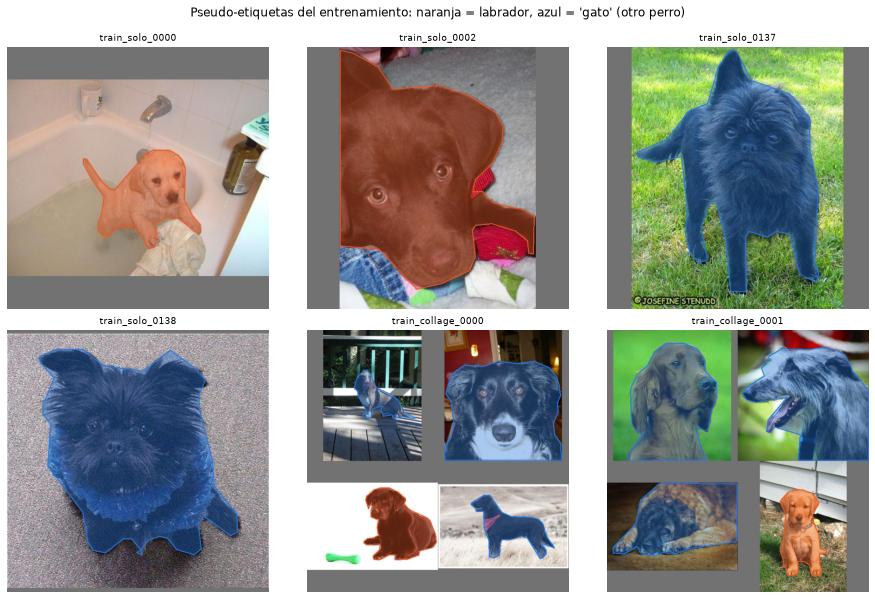

In [3]:
def leer_etiquetas(ruta_txt, ancho, alto):
    out = []
    for linea in Path(ruta_txt).read_text().splitlines():
        v = linea.split()
        if not v:
            continue
        pts = (np.array(v[1:], float).reshape(-1, 2) * [ancho, alto]).astype(np.int32)
        out.append((int(v[0]), pts))
    return out


def dibujar_etiquetas(ruta_img):
    rgb = np.asarray(Image.open(ruta_img).convert("RGB")).copy()
    capa = rgb.copy()
    h, w = rgb.shape[:2]
    for cls, pts in leer_etiquetas(Path(str(ruta_img).replace("images", "labels")).with_suffix(".txt"), w, h):
        cv2.fillPoly(capa, [pts], COLORES[cls])
        cv2.polylines(rgb, [pts], True, COLORES[cls], 2)
    return cv2.addWeighted(capa, 0.4, rgb, 0.6, 0)


rutas = sorted((DATASET / "images" / "train").glob("train_solo_*.jpg"))
labs = [r for r in rutas if Path(str(r).replace("images", "labels")).with_suffix(".txt").read_text().startswith("0")]
gatos = [r for r in rutas if r not in labs]
cols = sorted((DATASET / "images" / "train").glob("train_collage_*.jpg"))
muestra = [labs[0], labs[1], gatos[0], gatos[1], cols[0], cols[1]]

fig, ejes = plt.subplots(2, 3, figsize=(13, 8.6))
for eje, r in zip(ejes.ravel(), muestra):
    eje.imshow(dibujar_etiquetas(r)); eje.axis("off"); eje.set_title(r.stem, fontsize=9)
plt.suptitle("Pseudo-etiquetas del entrenamiento: naranja = labrador, azul = 'gato' (otro perro)", y=0.99)
plt.tight_layout()
plt.savefig(CARP / "dataset_muestra.png", dpi=70, bbox_inches="tight")
plt.show()

Las máscaras siguen bien el contorno general del perro, pero se nota que son automáticas: el pelaje y las patas no siempre quedan exactos. Es el techo de calidad del contorno que puede alcanzar el modelo que se entrena sobre ellas.

---

## 3. Entrenamiento

La configuración es la misma en los dos fine-tunings, para que la única diferencia sea el congelado: `yolov8n-seg.pt` como punto de partida, **40 épocas**, imagen de 640, lote de 16, semilla 0 y `mps` (GPU del Mac). El código está en `ejercicio5_finetune/entrenar.py`:

```python
m = YOLO("yolov8n-seg.pt")
m.train(data=".../data.yaml", epochs=40, imgsz=640, batch=16, seed=0, freeze=None)   # completo
m.train(data=".../data.yaml", epochs=40, imgsz=640, batch=16, seed=0, freeze=10)     # congelado
```

**Las dos corridas de 40 épocas tardan unos 20 minutos cada una en un M4, así que no se repiten dentro del notebook.** Las celdas cargan los **resultados guardados** de la corrida real (`resultados.json`, las curvas `curvas_*.csv` y los pesos `pesos/*.pt`), que son los generados por `entrenar.py`. Para repetirlo desde cero, `python ejercicio5_finetune/entrenar.py --data ejercicio5_finetune/_datos/dataset/data.yaml --runs runs --out ejercicio5_finetune` (el valor `mAP` exacto puede variar un poco entre ejecuciones por el no determinismo de la GPU).

Cuánto se congela con `freeze=10`:

In [4]:
modelo_base = YOLO("yolov8n-seg.pt")
total = sum(p.numel() for p in modelo_base.model.parameters())
# Ultralytics congela los parametros de las capas model.0 ... model.9 (el backbone) con freeze=10
congelados = sum(p.numel() for n, p in modelo_base.model.named_parameters()
                 if int(n.split(".")[1]) < 10)
print(f"Parametros totales : {total / 1e6:.2f} M")
print(f"Congelados (capas 0 a 9, backbone): {congelados / 1e6:.2f} M ({100 * congelados / total:.0f}%)")
print(f"Entrenables en la variante congelada: {(total - congelados) / 1e6:.2f} M")

Parametros totales : 3.41 M
Congelados (capas 0 a 9, backbone): 1.27 M (37%)
Entrenables en la variante congelada: 2.14 M


---

## 4. Resultados en el conjunto de prueba

Las métricas son **mAP de máscara** sobre el conjunto de prueba (46 fotos sueltas y 21 collages, con 130 instancias), que el modelo nunca vio ni usó para elegir el mejor punto de la corrida.

- **mAP50**: una máscara cuenta como acierto si se superpone al menos 50% con la verdadera.
- **mAP50-95**: promedio exigiendo de 50% a 95%, es decir, mide la **precisión del contorno**.

**El baseline no puede evaluarse "por clase".** `yolov8n-seg.pt` no tiene las clases "labrador" y "gato": solo conoce "dog". Por eso, además de la métrica por clase (que solo pueden producir los modelos entrenados), se mide una **métrica agnóstica a la clase** (`single_cls`), donde cuenta únicamente "¿encontró y segmentó bien al perro?", sin importar la etiqueta. Esa es la única comparación justa con el baseline.

In [5]:
res = json.loads((CARP / "resultados.json").read_text())
fila = lambda k, d: {"modelo": k, "mAP50": d["mAP50"], "mAP50-95": d["mAP50-95"], "precision": d["P"], "recall": d["R"]}

tabla_clase = pd.DataFrame([
    {**fila("Baseline (sin entrenar)", res["baseline_agnostico"]), "nota": "no aplica: no tiene estas clases"},
    {**fila("Fine-tuning completo", res["completo"])},
    {**fila("Fine-tuning backbone congelado", res["congelado"])},
]).set_index("modelo")
tabla_ag = pd.DataFrame([
    fila("Baseline (sin entrenar)", res["baseline_agnostico"]),
    fila("Fine-tuning completo", res["completo_agnostico"]),
    fila("Fine-tuning backbone congelado", res["congelado_agnostico"]),
]).set_index("modelo")

print("A) Segmentar al perro sin importar la clase (comparable con el baseline):")
display(tabla_ag.round(3))
print("\nB) Segmentar Y distinguir labrador de 'gato' (solo los modelos entrenados):")
display(tabla_clase.drop(index="Baseline (sin entrenar)").drop(columns="nota").round(3))
por_clase = pd.DataFrame({
    "Completo": res["completo"]["mAP50-95_por_clase"],
    "Congelado": res["congelado"]["mAP50-95_por_clase"]}, index=["labrador", "gato"])
print("\nmAP50-95 de mascara por clase:")
display(por_clase.round(3))

A) Segmentar al perro sin importar la clase (comparable con el baseline):


,mAP50,mAP50-95,precision,recall
modelo,,,,
Baseline (sin entrenar),0.881,0.759,0.722,0.885
Fine-tuning completo,0.978,0.785,0.961,0.962
Fine-tuning backbone congelado,0.992,0.810,0.954,0.992



B) Segmentar Y distinguir labrador de 'gato' (solo los modelos entrenados):


,mAP50,mAP50-95,precision,recall
modelo,,,,
Fine-tuning completo,0.885,0.717,0.786,0.833
Fine-tuning backbone congelado,0.854,0.706,0.695,0.904



mAP50-95 de mascara por clase:


,Completo,Congelado
labrador,0.695,0.639
gato,0.739,0.774


### Curvas de entrenamiento

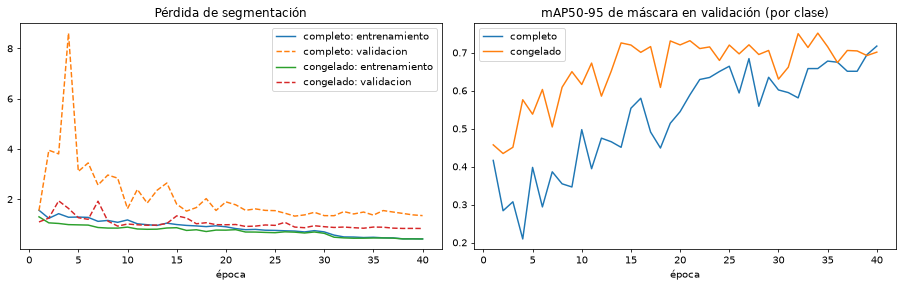

completo  : mejor mAP50-95 de validación 0.717 en la época 40 de 40
congelado : mejor mAP50-95 de validación 0.751 en la época 34 de 40


In [6]:
curvas = {n: pd.read_csv(CARP / f"curvas_{n}.csv") for n in ["completo", "congelado"]}
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for n, df in curvas.items():
    ejes[0].plot(df["epoch"], df["train/seg_loss"], label=f"{n}: entrenamiento")
    ejes[0].plot(df["epoch"], df["val/seg_loss"], "--", label=f"{n}: validacion")
    ejes[1].plot(df["epoch"], df["metrics/mAP50-95(M)"], label=n)
ejes[0].set_title("Pérdida de segmentación"); ejes[0].set_xlabel("época"); ejes[0].legend()
ejes[1].set_title("mAP50-95 de máscara en validación (por clase)"); ejes[1].set_xlabel("época"); ejes[1].legend()
plt.tight_layout(); plt.savefig(CARP / "curvas.png", dpi=70, bbox_inches="tight"); plt.show()
for n, df in curvas.items():
    m = df["metrics/mAP50-95(M)"]
    print(f"{n:<10}: mejor mAP50-95 de validación {m.max():.3f} en la época {int(df['epoch'][m.idxmax()])} de {len(df)}")

---

## 5. Resultados vistos en imágenes del conjunto de prueba

Tres imágenes que ningún modelo vio en el entrenamiento: un labrador, otro perro y un collage de cuatro razas. Los colores de las máscaras indican la clase predicha (para el baseline, que solo dice "dog", se usa su propio color).

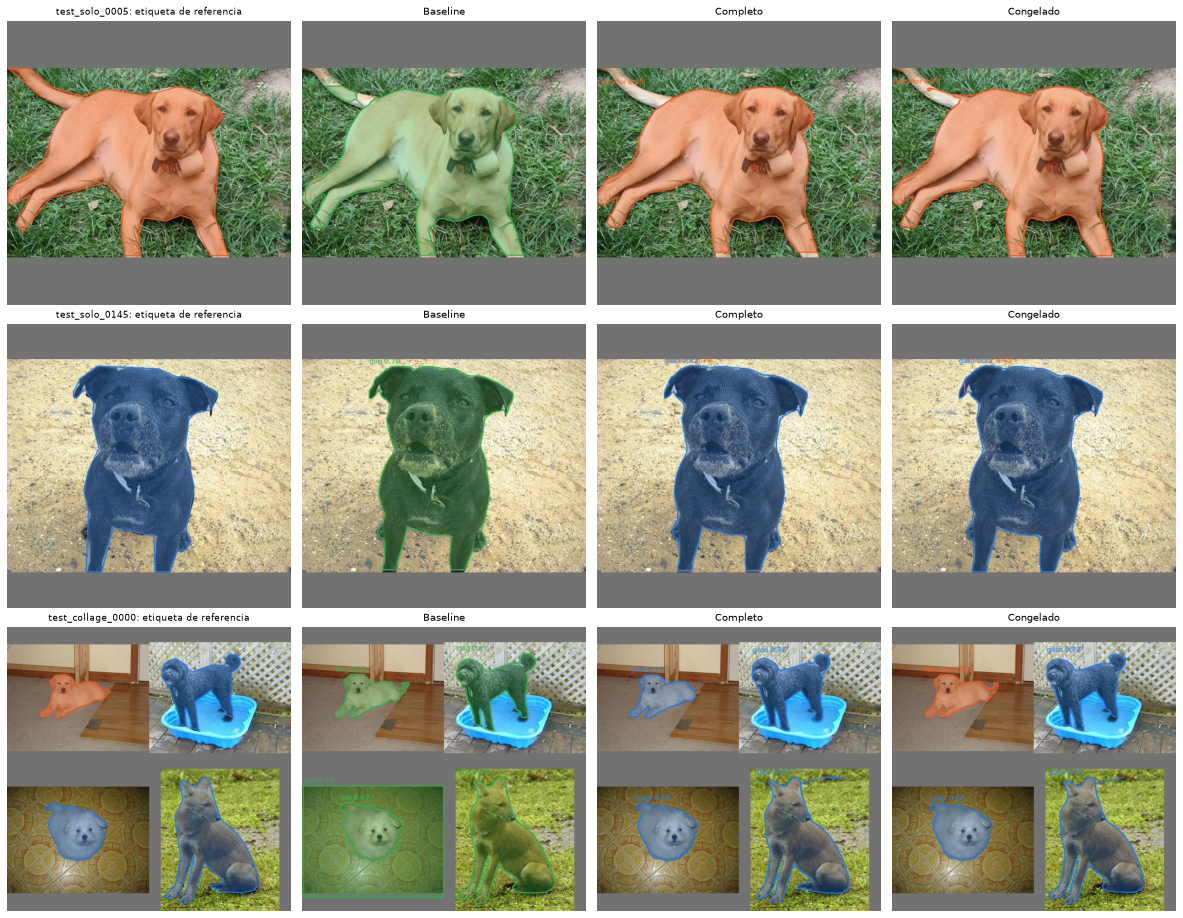

In [7]:
MODELOS = {
    "Baseline": YOLO("yolov8n-seg.pt"),
    "Completo": YOLO(str(CARP / "pesos" / "completo.pt")),
    "Congelado": YOLO(str(CARP / "pesos" / "congelado.pt")),
}


def predecir(modelo, rgb, conf=0.25):
    r = modelo(rgb[..., ::-1], conf=conf, retina_masks=True, verbose=False, device="cpu")[0]
    return r


def pintar(rgb, r):
    salida = rgb.copy()
    capa = rgb.copy()
    if r.masks is None:
        return salida
    for caja, pts in zip(r.boxes, r.masks.xy):
        nombre = r.names[int(caja.cls)]
        color = {"labrador": COLORES[0], "gato": COLORES[1]}.get(nombre, (60, 170, 80))
        p = pts.astype(np.int32)
        cv2.fillPoly(capa, [p], color)
        cv2.polylines(salida, [p], True, color, 2)
        x, y = p[:, 0].min(), max(p[:, 1].min() - 6, 14)
        cv2.putText(salida, f"{nombre} {float(caja.conf):.2f}", (int(x), int(y)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return cv2.addWeighted(capa, 0.35, salida, 0.65, 0)


def tiene_clase(ruta, c):
    return any(l.startswith(f"{c} ") for l in Path(str(ruta).replace("images", "labels")).with_suffix(".txt").read_text().splitlines())


solos = sorted((DATASET / "images" / "test").glob("test_solo_*.jpg"))
colls = sorted((DATASET / "images" / "test").glob("test_collage_*.jpg"))
elegidas = [next(r for r in solos if tiene_clase(r, 0)), next(r for r in solos if not tiene_clase(r, 0)), colls[0]]

fig, ejes = plt.subplots(len(elegidas), 4, figsize=(17, 4.4 * len(elegidas)))
for i, ruta in enumerate(elegidas):
    rgb = np.asarray(Image.open(ruta).convert("RGB"))
    ejes[i, 0].imshow(dibujar_etiquetas(ruta)); ejes[i, 0].set_title(f"{ruta.stem}: etiqueta de referencia", fontsize=9)
    for j, (nombre, m) in enumerate(MODELOS.items(), start=1):
        ejes[i, j].imshow(pintar(rgb, predecir(m, rgb))); ejes[i, j].set_title(nombre, fontsize=10)
    for e in ejes[i]:
        e.axis("off")
plt.tight_layout(); plt.savefig(CARP / "predicciones_test.png", dpi=70, bbox_inches="tight"); plt.show()

---

## 6. ¿Qué pasa con lo que ya sabía? Las fotos del Ejercicio 4

Al fine-tunear con solo dos clases, la cabeza de clasificación del modelo se reemplaza: el modelo nuevo **ya no tiene una clase "persona", "bus" ni "corbata"**. A esto se le llama **olvido catastrófico**: aprender la tarea nueva borra capacidades de la anterior. Se comprueba con las cinco fotos de prueba del Ejercicio 4 (perro, gato, dos personas con corbata, calle con un bus, persona de uniforme).

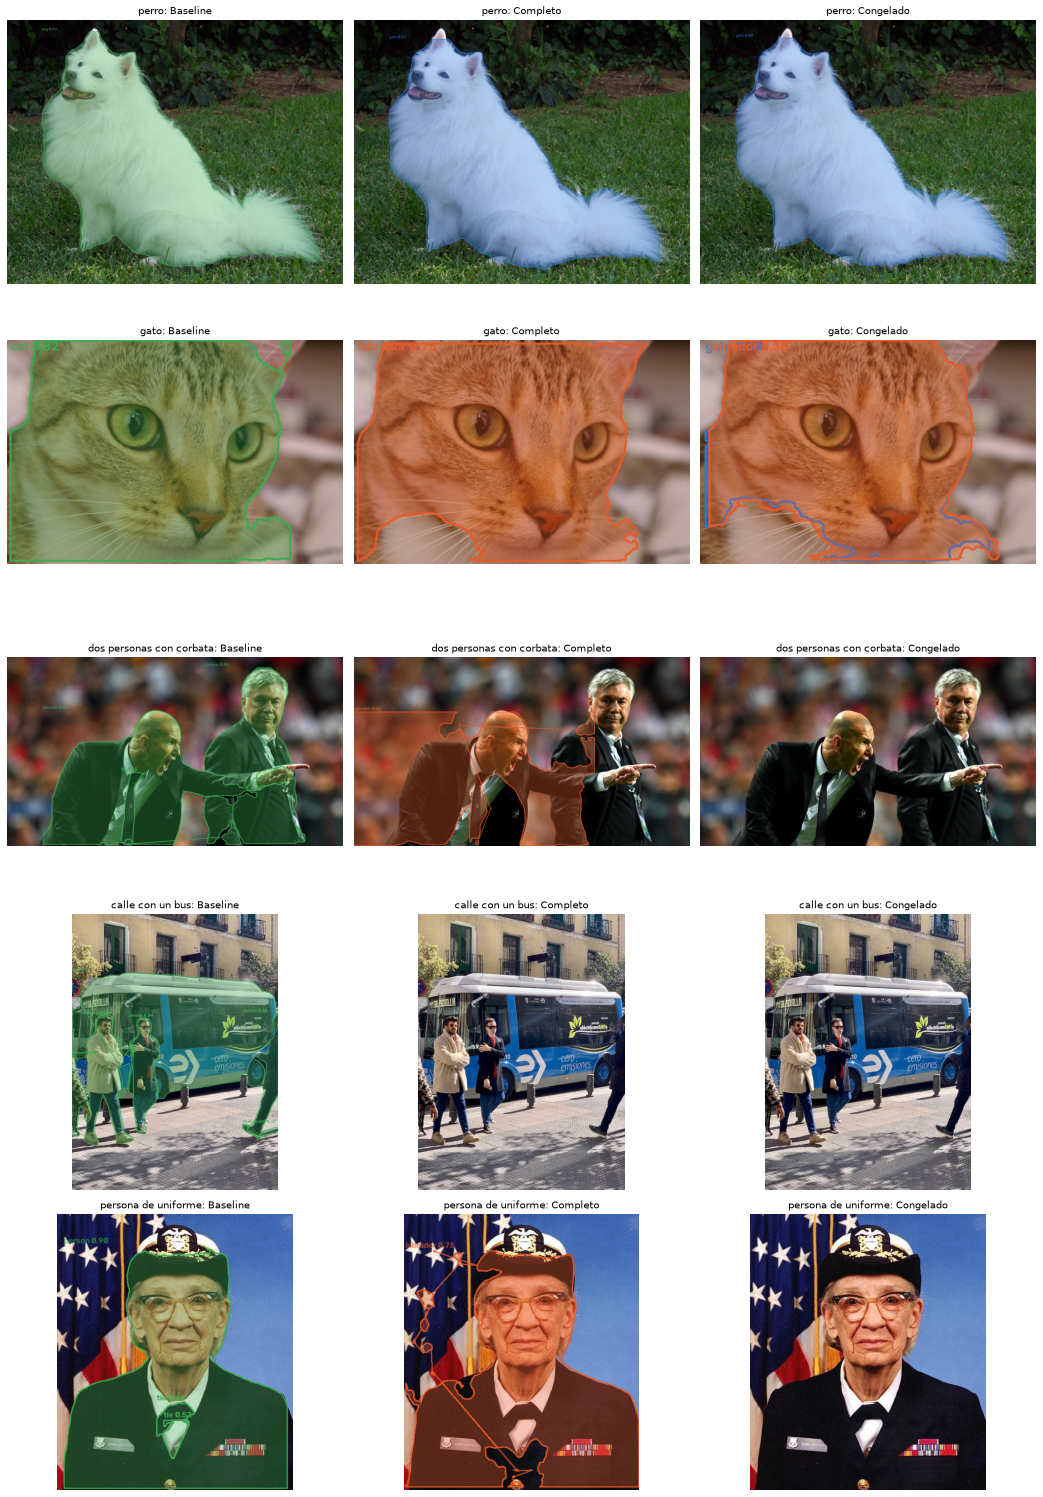

modelo,Baseline,Completo,Congelado
imagen,,,
calle con un bus,"person x4, bus x1, skateboard x1",ninguna,ninguna
dos personas con corbata,"person x2, tie x1",labrador x1,ninguna
gato,cat x1,labrador x1,"gato x1, labrador x1"
perro,dog x1,gato x1,gato x1
persona de uniforme,"person x1, tie x2",labrador x1,ninguna


In [8]:
IMG_EX4 = DATOS / "imagenes_ex4"
IMG_EX4.mkdir(parents=True, exist_ok=True)
MUESTRAS = {
    1: ("perro", "https://github.com/pytorch/hub/raw/master/images/dog.jpg", "perro.jpg"),
    2: ("gato", "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.0/skimage/data/chelsea.png", "gato.png"),
    3: ("dos personas con corbata", "https://ultralytics.com/images/zidane.jpg", "personas_corbata.jpg"),
    4: ("calle con un bus", "https://ultralytics.com/images/bus.jpg", "calle_bus.jpg"),
    5: ("persona de uniforme", None, "uniforme.jpg"),
}
RUTAS4 = {}
for n, (nombre, url, archivo) in MUESTRAS.items():
    destino = IMG_EX4 / archivo
    if not destino.exists():
        if url is None:
            destino.write_bytes((Path(matplotlib.get_data_path()) / "sample_data" / "grace_hopper.jpg").read_bytes())
        else:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            destino.write_bytes(urllib.request.urlopen(req, timeout=30).read())
    RUTAS4[n] = destino

imgs4 = {n: np.asarray(Image.open(r).convert("RGB")) for n, r in RUTAS4.items()}
if max(max(a.shape[:2]) for a in imgs4.values()) > 1920:
    imgs4 = {n: cv2.resize(a, None, fx=1920 / max(a.shape[:2]), fy=1920 / max(a.shape[:2])) if max(a.shape[:2]) > 1920 else a for n, a in imgs4.items()}

fig, ejes = plt.subplots(len(MUESTRAS), 3, figsize=(15, 4.3 * len(MUESTRAS)))
filas = []
for i, (n, (nombre, _, _)) in enumerate(MUESTRAS.items()):
    for j, (mn, m) in enumerate(MODELOS.items()):
        r = predecir(m, imgs4[n])
        ejes[i, j].imshow(pintar(imgs4[n], r)); ejes[i, j].axis("off"); ejes[i, j].set_title(f"{nombre}: {mn}", fontsize=10)
        cuenta = {}
        for c in r.boxes.cls.tolist():
            cuenta[r.names[int(c)]] = cuenta.get(r.names[int(c)], 0) + 1
        filas.append({"imagen": nombre, "modelo": mn, "detecciones": ", ".join(f"{k} x{v}" for k, v in cuenta.items()) or "ninguna"})
plt.tight_layout(); plt.savefig(CARP / "olvido_ejercicio4.png", dpi=60, bbox_inches="tight"); plt.show()
display(pd.DataFrame(filas).pivot(index="imagen", columns="modelo", values="detecciones")[list(MODELOS)])

---

## 7. Conclusiones

**Lo que el fine-tuning sí logró: enseñarle al modelo una distinción que no tenía.** El baseline solo conoce "dog" y no puede decir si un perro es labrador. Los dos modelos entrenados lo hacen sobre perros que nunca vieron, con mAP50 de máscara de 0.885 (completo) y 0.854 (congelado) separando las dos clases.

**Lo que no logró: mejorar el contorno de forma clara.** Medido sin importar la clase (la única comparación justa con el baseline), el mAP50-95 pasa de 0.759 (baseline) a 0.785 (completo) y 0.810 (congelado). Es una mejora pequeña y hay que leerla con cuidado: el conjunto de prueba tiene solo 130 instancias, hay una sola corrida (una semilla) por variante, y las máscaras de referencia son pseudo-etiquetas de `yolov8m-seg`, así que parte de la "mejora" es que el modelo pequeño aprende a imitar los contornos del modelo mediano, no a acercarse a la realidad. La diferencia entre completo y congelado, de 0.025, no es suficiente para declarar un ganador.

**Completo contra congelado: depende de qué se mire.** Segmentando al perro sin importar la clase, el congelado sale mejor (0.810 contra 0.785 y recall de 0.992). Pero distinguiendo la clase, el completo es mejor, sobre todo en labrador: 0.695 contra 0.639 de mAP50-95 en esa clase. Es coherente con la intuición: con el backbone congelado las características se conservan y la forma del perro se segmenta bien, pero separar un labrador de un Chesapeake Bay o un Flat Coated Retriever necesita adaptar también las características, y eso solo lo permite el entrenamiento completo. En precisión por clase el congelado quedó más bajo (0.695 contra 0.786), es decir, produce más falsos positivos.

**El olvido es real y es el costo de este esquema.** En la sección 6 los modelos entrenados dejaron de reconocer lo que sabía el baseline: ya no hay `person`, `bus` ni `tie`, y el bus y las personas de la calle no se detectan. Peor que olvidar es **inventar**: el modelo completo marcó como `labrador` una detección en las dos fotos de personas con corbata y de uniforme, y también en la del gato, con máscaras irregulares, porque con solo dos clases cualquier cosa se parece a alguna de ellas. El congelado se equivocó menos con personas (no detectó ninguna), pero también etiquetó el gato de la foto como `gato` y como `labrador`. Para conservar las 80 clases habría que mezclar datos de COCO en el entrenamiento, congelar más capas o usar una cabeza adicional; aquí no se hizo.

**Un ejemplo concreto de los límites de la distinción.** En el collage de la sección 5, el cachorro de labrador de la esquina superior izquierda lo clasificó bien el congelado y mal el completo (lo llamó `gato`). Es una sola imagen, no una conclusión, pero ilustra que con tan pocos datos la frontera labrador contra no labrador es frágil.

**Limitaciones que hay que tener presentes.**
- "Gato" significa "perro que no es labrador": es una convención de la práctica, no hay gatos reales en los datos.
- Las máscaras son pseudo-etiquetas de YOLO, no anotación humana; fijan el techo de calidad del contorno.
- Pocos datos (311 fotos de origen, 136 labradores, 175 de 30 razas) y 67 imágenes de prueba, con collages que reutilizan las mismas fotos dentro de cada partición: los números tienen bastante incertidumbre y no se repitieron con varias semillas.
- Las razas del conjunto de prueba son las mismas 30 del entrenamiento (con fotos distintas): no se midió cómo le va con razas nunca vistas.
- El baseline y los modelos entrenados no son comparables por clase, solo en la métrica agnóstica.
